In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:


# df = pd.read_csv(r'D:\proj\howamachinelearns\fruitsandveggies\ProductPriceIndex.csv')
df = pd.read_csv(r'/Users/christianmarchello/Documents/howamachinelearns/fruitsandveggies/ProductPriceIndex.csv')
currency_columns = ['farmprice', 'atlantaretail', 'chicagoretail', 'losangelesretail','newyorkretail']
for col in currency_columns:
     df[col] = df[col].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False)
     df[col] = pd.to_numeric(df[col])
     
     
print(df.dtypes)

print(len(df))

productname          object
date                 object
farmprice           float64
atlantaretail       float64
chicagoretail       float64
losangelesretail    float64
newyorkretail       float64
averagespread        object
dtype: object
15766


In [6]:
###splitting date column and assinging season

# seasons = {"spring":[3,4,5], "summer":[6,7,8], "fall":[9,10,11], "winter":[12,1,2]}


df_dates_split = df.assign(
    year = lambda x: x["date"].str.split("-").str[0].astype(int),
    month = lambda x: x["date"].str.split("-").str[1].astype(int),
    day = lambda x: x["date"].str.split("-").str[2].astype(int)
)


        
print(df_dates_split)









            productname        date  farmprice  atlantaretail  chicagoretail  \
0          Strawberries  2019-05-19       1.16           2.23           1.70   
1       Romaine Lettuce  2019-05-19       0.35           1.72           2.00   
2      Red Leaf Lettuce  2019-05-19       0.32           1.84           1.84   
3              Potatoes  2019-05-19       1.50           5.32           5.14   
4               Oranges  2019-05-19       0.41           1.42           1.45   
...                 ...         ...        ...            ...            ...   
15761   Broccoli Crowns  1999-10-24       0.29           1.46           0.00   
15762  Broccoli Bunches  1999-10-24       0.23           1.21           0.00   
15763       Cauliflower  1999-10-24       0.19           1.01           0.00   
15764           Carrots  1999-10-24       0.12           0.64           0.00   
15765        Cantaloupe  1999-10-24       0.21           0.54           0.00   

       losangelesretail  newyorkretail 

In [7]:
df_dates_split.loc[df_dates_split['month'].isin([3, 4, 5]), 'season'] = 'spring'
df_dates_split.loc[df_dates_split['month'].isin([6, 7, 8]), 'season'] = 'summer'
df_dates_split.loc[df_dates_split['month'].isin([9, 10, 11]), 'season'] = 'fall'
df_dates_split.loc[df_dates_split['month'].isin([12, 1, 2]), 'season'] = 'winter'

print(df_dates_split)



        

    

            productname        date  farmprice  atlantaretail  chicagoretail  \
0          Strawberries  2019-05-19       1.16           2.23           1.70   
1       Romaine Lettuce  2019-05-19       0.35           1.72           2.00   
2      Red Leaf Lettuce  2019-05-19       0.32           1.84           1.84   
3              Potatoes  2019-05-19       1.50           5.32           5.14   
4               Oranges  2019-05-19       0.41           1.42           1.45   
...                 ...         ...        ...            ...            ...   
15761   Broccoli Crowns  1999-10-24       0.29           1.46           0.00   
15762  Broccoli Bunches  1999-10-24       0.23           1.21           0.00   
15763       Cauliflower  1999-10-24       0.19           1.01           0.00   
15764           Carrots  1999-10-24       0.12           0.64           0.00   
15765        Cantaloupe  1999-10-24       0.21           0.54           0.00   

       losangelesretail  newyorkretail 

/var/folders/cs/j8zp0cms6vq0cmpk_cyy1kn00000gn/T/ipykernel_70363/1122427700.py:1: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value 'spring' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df_dates_split.loc[df_dates_split['month'].isin([3, 4, 5]), 'season'] = 'spring'


In [8]:
### creating specific tables for each specific fruit/veggie

table_by_productname = {}

for key_value, grouped_df in df_dates_split.groupby('productname'):
    table_by_productname[key_value] = grouped_df.reset_index(drop=True)



# print(table_by_productname)
for key in table_by_productname:
    print("\nDataFrame for key:" +  key)
    print(table_by_productname[key])
    




DataFrame for key:Asparagus
    productname        date  farmprice  atlantaretail  chicagoretail  \
0     Asparagus  2019-04-14       2.43           2.48           1.88   
1     Asparagus  2019-04-07       2.43           2.65           2.73   
2     Asparagus  2019-03-31       2.34           2.45           2.13   
3     Asparagus  2018-05-13       2.43           2.48           2.07   
4     Asparagus  2018-05-06       2.80           2.47           2.56   
..          ...         ...        ...            ...            ...   
256   Asparagus  2000-02-06       0.96           2.64           0.00   
257   Asparagus  2000-01-30       1.20           2.69           0.00   
258   Asparagus  2000-01-23       1.35           3.39           0.00   
259   Asparagus  2000-01-16       1.49           3.39           0.00   
260   Asparagus  2000-01-09       2.05           3.39           0.00   

     losangelesretail  newyorkretail averagespread  year  month  day  season  
0                2.49      

In [13]:
print (table_by_productname.keys())

dict_keys(['Asparagus', 'Avocados', 'Broccoli Bunches', 'Broccoli Crowns', 'Cantaloupe', 'Carrots', 'Cauliflower', 'Celery', 'Flame Grapes', 'Green Leaf Lettuce', 'Honeydews', 'Iceberg Lettuce', 'Nectarines', 'Oranges', 'Peaches', 'Plums', 'Potatoes', 'Red Leaf Lettuce', 'Romaine Lettuce', 'Strawberries', 'Thompson Grapes', 'Tomatoes'])


In [17]:
for key in table_by_productname:
    data = table_by_productname[key]
    print(data)



    productname        date  farmprice  atlantaretail  chicagoretail  \
0     Asparagus  2019-04-14       2.43           2.48           1.88   
1     Asparagus  2019-04-07       2.43           2.65           2.73   
2     Asparagus  2019-03-31       2.34           2.45           2.13   
3     Asparagus  2018-05-13       2.43           2.48           2.07   
4     Asparagus  2018-05-06       2.80           2.47           2.56   
..          ...         ...        ...            ...            ...   
256   Asparagus  2000-02-06       0.96           2.64           0.00   
257   Asparagus  2000-01-30       1.20           2.69           0.00   
258   Asparagus  2000-01-23       1.35           3.39           0.00   
259   Asparagus  2000-01-16       1.49           3.39           0.00   
260   Asparagus  2000-01-09       2.05           3.39           0.00   

     losangelesretail  newyorkretail averagespread  year  month  day  season  
0                2.49           1.61       -12.96%  2019

<Axes: xlabel='year', ylabel='farmprice'>

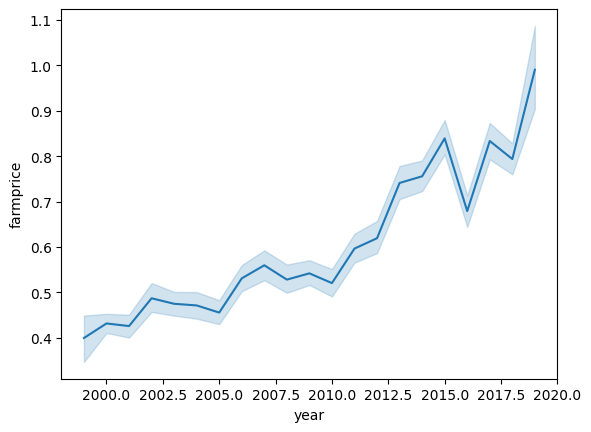

In [18]:
df_dates_split

sns.lineplot(data=df_dates_split, x="year", y="farmprice")

In [57]:

grouped = df_dates_split.groupby(['productname','year','month'])
farmpriceagg = (grouped['farmprice'].mean()).to_frame()
losangelesretailagg = (grouped['losangelesretail'].mean()).to_frame()
print(farmpriceagg)

                        farmprice
productname year month           
Asparagus   2000 1       1.522500
                 2       0.937500
                 3       0.852500
                 4       1.138000
                 5       0.935000
...                           ...
Tomatoes    2018 6       0.320000
                 7       0.364000
                 8       0.445000
                 9       0.484000
                 10      0.573333

[3874 rows x 1 columns]


# analysis/what do we want to figure out from the data

the data has product prices daily for the last 20 years, what could i graph/generalize to understand relationships between columns

if i wanted to do monthly analysis i would need to check if every day is supplied for a months price data (for a product), meaning groupby by product name and month, and print out the amount of records for each month

group by monthly and name = price avg by month across all years

group by year and name = price avg

## plotting season average farmprice (or any price) for all products, aggreggated by season (all years)

a point would represent the season average farm price by season across all years (not aggregated by year), should be 4 points (a point a season)

### a plot point would be: the season average "type of price" during this season across the last 20 years


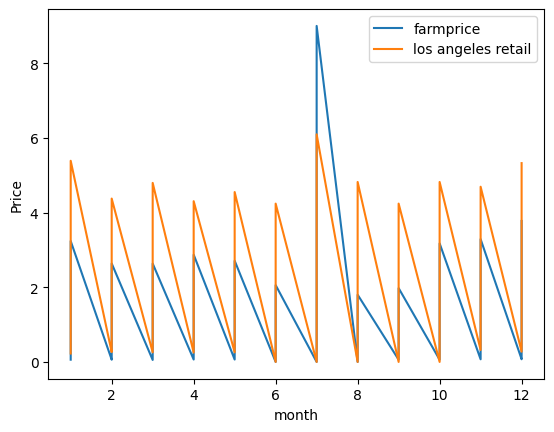

In [59]:

sns.lineplot(data=farmpriceagg, x="month", y="farmprice", label="farmprice", estimator=None)
sns.lineplot(data=losangelesretailagg, x="month", y="losangelesretail", label="los angeles retail", estimator=None)
# sns.lineplot(data=farmpriceagg, x="year", y="newyorkretail", label="newyorkretail", estimator=None)
# sns.lineplot(data=farmpriceagg, x="year", y="chicagoretail", label="chicagoretail", estimator=None)
# sns.lineplot(data=df_dates_split, x="year", y="atlantaretail", label="atlantaretail", estimator=None)
# x_axis = sorted(farmpriceaggbynameavg['year'].unique())
plt.ylabel("Price")
# plt.xticks(x_axis, rotation =45)
plt.legend()
plt.show()

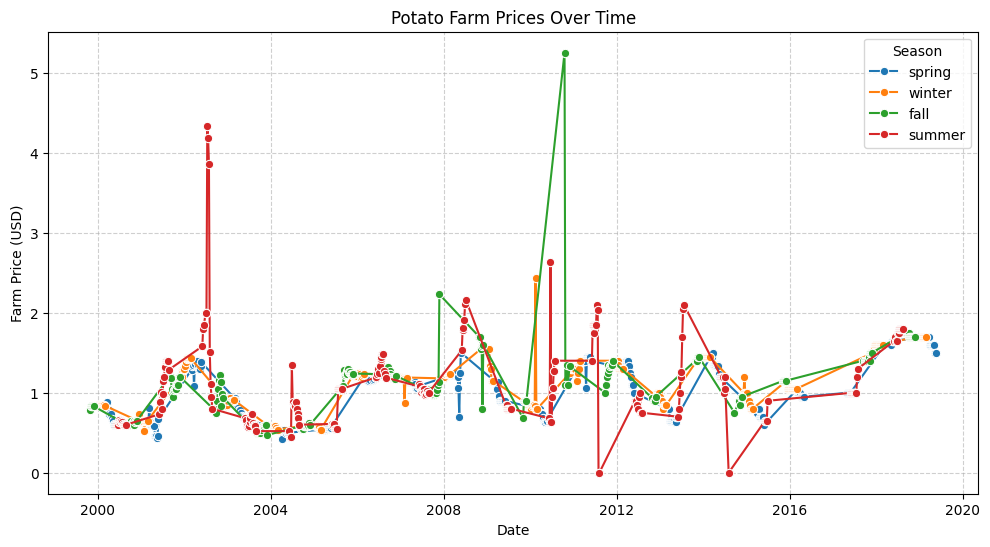

In [8]:
#('line', 'bar', 'barh', 'kde', 'density', 'area', 'hist', 'box', 'pie', 'scatter', 'hexbin')

# potatoes = df_dates_split[df_dates_split['season'] == "fall"].copy(deep=True)
potatoes = df_dates_split.copy(deep=True)

# print(specific_season)
# potatoes = potatoes.sort_values(by=['year', 'month', 'day'])
# print(potatoes)
# plt.figure(figsize=(10, 6))
# sns.lineplot(data=potatoes, x='day', y='farmprice', hue='season', marker='o')

# days = sorted(potatoes['day'].unique())
# plt.xticks(days, rotation=45)

# plt.title("Daily Potato Farm Prices by season")
# plt.xlabel("Day of Month")
# plt.ylabel("Farm Price (USD)")
# plt.grid(True, linestyle='--', alpha=0.6)
# plt.legend(title="season")


# plt.show()
# Ensure date is datetime type
potatoes['date'] = pd.to_datetime(potatoes['date'])

plt.figure(figsize=(12,6))
sns.lineplot(data=potatoes, x='date', y='farmprice', hue='season', marker='o')
years = sorted(potatoes['year'].unique())

# plt.xticks(years, rotation=45)

plt.title("Potato Farm Prices Over Time")
plt.xlabel("Date")
plt.ylabel("Farm Price (USD)")

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title="Season")
plt.show()


### Monthly Potato Price Avg by Season (All time)


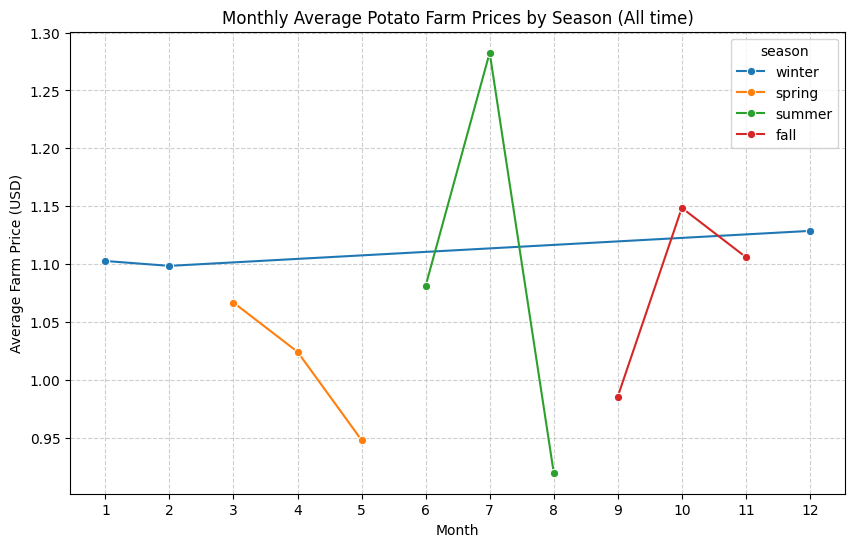

In [210]:
# Aggregate to monthly average farm prices
monthly_avg = (
    potatoes.groupby(['month', 'season'], as_index=False)['farmprice']
    .mean()
)



# Plot monthly averages grouped by year
plt.figure(figsize=(10, 6))
sns.lineplot(data=monthly_avg, x='month', y='farmprice', hue='season', marker='o')

plt.title("Monthly Average Potato Farm Prices by Season (All time)")
plt.xlabel("Month")
plt.ylabel("Average Farm Price (USD)")
plt.xticks(range(1, 13))
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title="season")
plt.show()


### Yearly Average Potato Farm Prices by Season (All time)


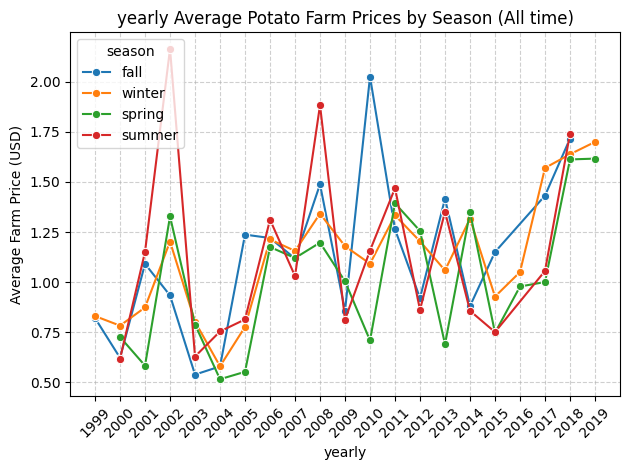

In [220]:
# Aggregate to yearly average farm prices
yearly_avg = (
    potatoes.groupby(['year', 'season'], as_index=False)['farmprice']
    .mean()
)



# Plot yearly averages grouped by year

sns.lineplot(data=yearly_avg, x='year', y='farmprice', hue='season', marker='o')

plt.title("yearly Average Potato Farm Prices by Season (All time)")
plt.xlabel("yearly")
plt.ylabel("Average Farm Price (USD)")
years = sorted(yearly_avg['year'].unique())
plt.xticks(years, rotation=45)  # rotation helps readability

plt.grid(True, linestyle='--', alpha=0.6)
# plt.xticks(range(1, 13))
# plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title="season")
plt.tight_layout()
plt.show()

### Now using all fruits and vegetables to generalize prices across farms and commercial locations
